**NAMA : Alysha Khanza Dwi Avianti**

**NPM : 24083010123**

**Kelas Analisis Deret Waktu A**

link repo: https://github.com/alyshakhanza/donor-hb-rejection

# Pengumpulan Data dan Pembuktian Non-Stasioneritas
**Objek:** Jumlah calon pendonor darah yang ditolak karena kadar hemoglobin (HB) di UDD PMI Kota Surabaya  
**Data:** `data_tolak_hb.csv`, agregasi harian 1 Januari – 31 Agustus 2026 (243 hari)  
**Tujuan:** Membuktikan bahwa data bersifat **non-stasioner** melalui plot rata-rata bulanan, dekomposisi STL, ACF, serta uji formal ADF dan KPSS.


## 1. Memuat Data
Membaca file CSV, mengubah kolom `TglPeriksa` menjadi tanggal (index), lalu memastikan frekuensi harian (`asfreq("D")`) agar tidak ada hari yang terlewat.

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

def muat_data(path):
    d = pd.read_csv(path, parse_dates=["TglPeriksa"], index_col="TglPeriksa")
    return d["Jumlah_Pendonor"].asfreq("D").rename("pendonor")

y = muat_data("data_tolak_hb.csv")
print(len(y), "hari | missing:", y.isna().sum())

243 hari | missing: 0


**Hasil:** Data terdiri dari 243 hari observasi tanpa nilai kosong (*missing* = 0), sehingga deret waktu utuh dan siap dianalisis.

## 2. Plot Data Harian dan Rata-rata Bulanan
Menampilkan data harian (garis biru) bersama rata-rata tiap bulan (garis merah). Jika deret stasioner, rata-rata seharusnya relatif konstan sepanjang waktu.

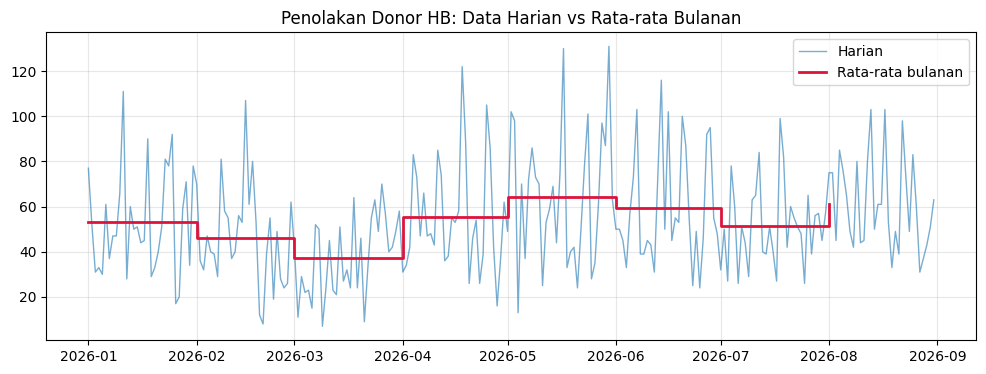

In [ ]:
rata_bln = y.resample("MS").mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y, lw=1, alpha=.6, label="Harian")
ax.step(rata_bln.index, rata_bln.values, where="post", color="crimson", lw=2, label="Rata-rata bulanan")
ax.set_title("Penolakan Donor HB: Data Harian vs Rata-rata Bulanan")
ax.legend(); ax.grid(alpha=.3); plt.show()

**Interpretasi:** Rata-rata bulanan tidak konstan. Nilainya turun dari sekitar 53 (Januari) ke titik terendah sekitar 37 (Maret), lalu naik ke puncak sekitar 64 (Mei), dan bergerak di kisaran 51–61 pada bulan-bulan berikutnya. Data harian juga berfluktuasi lebar (kisaran 7–131). Ini mengindikasikan mean yang berubah seiring waktu, sehingga data tidak stasioner.

## 3. Dekomposisi STL (Seasonal-Trend decomposition using LOESS)
Memisahkan deret menjadi tiga komponen dengan periode musiman 7 hari: **Trend** (arah jangka panjang), **Season** (pola berulang mingguan), dan **Resid** (sisa yang tidak terjelaskan).

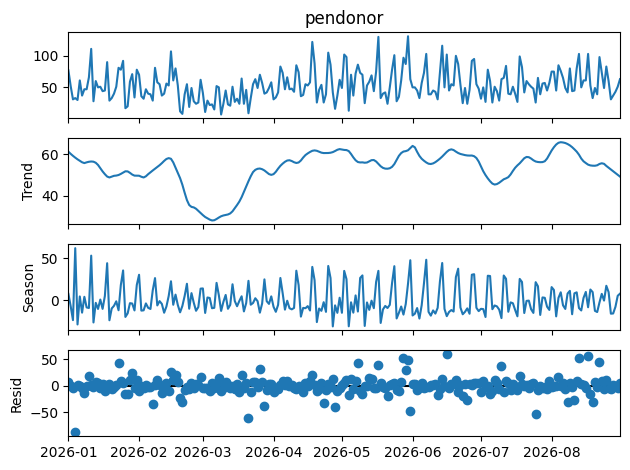

In [ ]:
stl = STL(y, period=7, robust=True).fit()
stl.plot(); plt.show()

**Interpretasi:**
- **Trend** tidak mendatar: turun tajam hingga titik terendah pada awal Maret, pulih pada akhir Maret, lalu bertahan di level lebih tinggi pada Mei–Agustus dengan beberapa penurunan. terbukti adanya tren yang berubah.
- **Season** menunjukkan pola naik-turun yang berulang secara teratur, mengonfirmasi adanya musiman mingguan.
- **Resid** tersebar di sekitar nol, artinya sebagian besar pola sudah ditangkap oleh tren dan musiman.

## 4. Autocorrelation Function (ACF)
Mengukur korelasi data dengan dirinya sendiri pada lag 1–35 hari. Batang yang keluar dari area pita biru (batas signifikansi 95%) berarti korelasinya signifikan.

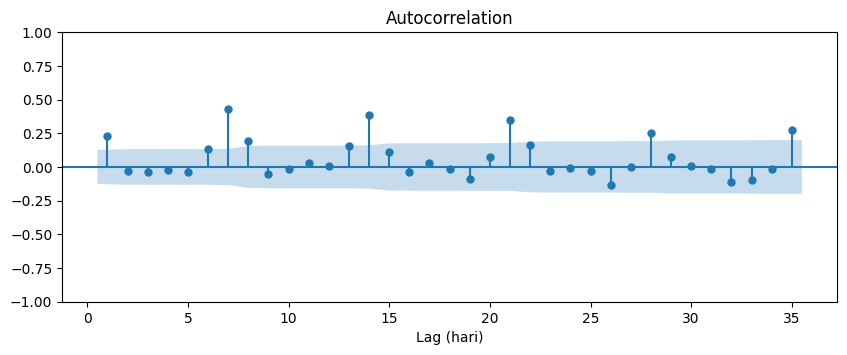

In [ ]:
plt.figure(figsize=(10, 3.5))
plot_acf(y, lags=35, zero=False, ax=plt.gca())
plt.xlabel("Lag (hari)"); plt.show()

**Interpretasi:** Korelasi signifikan muncul pada lag **7, 14, 21, 28, dan 35** (kelipatan 7) dengan nilai tertinggi sekitar 0,43 pada lag 7. Lag 1 juga signifikan (sekitar 0,23). Pola kelipatan 7 ini menunjukkan musiman mingguan (s = 7): jumlah penolakan hari ini mirip dengan hari yang sama pada minggu-minggu sebelumnya.

## 5. Uji Stasioneritas Formal: ADF dan KPSS
Dua uji dengan hipotesis yang berlawanan, sehingga hasilnya saling menguatkan:
- **ADF**: H0 = data tidak stasioner. Data stasioner jika p-value < 0,05.
- **KPSS**: H0 = data stasioner. Data tidak stasioner jika p-value < 0,05.

In [ ]:
adf = adfuller(y, autolag="AIC")
kp = kpss(y, regression="c", nlags="auto")

hasil = pd.DataFrame({
    "Uji": ["ADF", "KPSS"],
    "Statistik": [round(adf[0], 4), round(kp[0], 4)],
    "p-value": [round(adf[1], 4), round(kp[1], 4)],
    "H0": ["Tidak stasioner", "Stasioner"],
    "Keputusan": ["Gagal tolak H0 → non-stasioner" if adf[1] > 0.05 else "Tolak H0 → stasioner",
                  "Tolak H0 → non-stasioner" if kp[1] < 0.05 else "Gagal tolak H0 → stasioner"],
})
hasil

/tmp/ipykernel_464/1355038563.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kp = kpss(y, regression="c", nlags="auto")


,Uji,Statistik,p-value,H0,Keputusan
0,ADF,-1.8998,0.3322,Tidak stasioner,Gagal tolak H0 → non-stasioner
1,KPSS,0.9274,0.0100,Stasioner,Tolak H0 → non-stasioner


**Interpretasi:**

| Uji | Statistik | p-value | Keputusan |
|---|---|---|---|
| ADF | -1,8998 | 0,3322 | Gagal tolak H0 → non-stasioner |
| KPSS | 0,9274 | ≤ 0,01 | Tolak H0 → non-stasioner |

ADF memberi p-value 0,3322 (> 0,05), dan KPSS memberi p-value ≤ 0,01 (< 0,05). Kedua uji sama-sama menyimpulkan data non-stasioner.

## Kesimpulan
Data jumlah penolakan donor HB harian **bersifat non-stasioner**, dibuktikan oleh:
1. Rata-rata bulanan dan komponen tren yang berubah sepanjang waktu.
2. Pola musiman mingguan (ACF signifikan pada kelipatan lag 7).
3. Uji ADF (p = 0,3322) dan KPSS (p ≤ 0,01) yang sama-sama menunjukkan non-stasioner.



# PROGRESS 2: Pembagian Data, Baseline, dan Model SARIMA
**Tujuan:** Menyiapkan data latih dan uji, tolok ukur naif musiman, serta membangun model SARIMA sebagai pembanding bagi LSTM.


## 6. Pembagian Data Latih dan Uji
Data dibagi secara kronologis (tanpa pengacakan) dengan rasio 80:20.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

y = pd.read_csv("data_tolak_hb.csv", parse_dates=["TglPeriksa"], index_col="TglPeriksa")["Jumlah_Pendonor"].asfreq("D")
print(len(y), "hari")

243 hari


Latih: 194 hari (2026-01-01 s.d. 2026-07-13)
Uji  : 49 hari (2026-07-14 s.d. 2026-08-31)


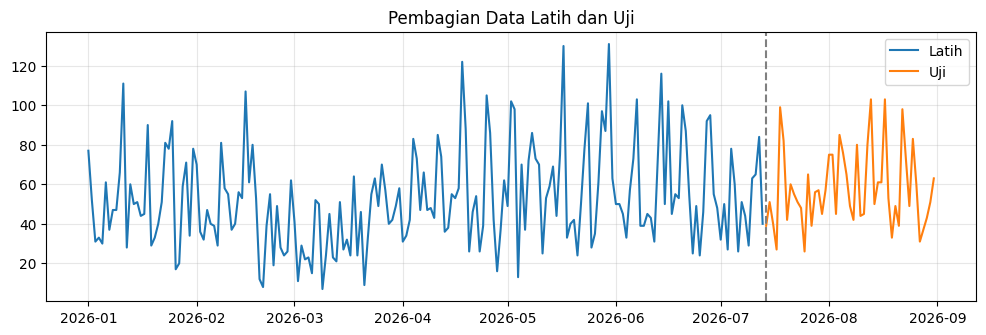

In [ ]:
rasio_latih = 0.8
n_latih = int(len(y) * rasio_latih)
latih, uji = y.iloc[:n_latih], y.iloc[n_latih:]

print(f"Latih: {len(latih)} hari ({latih.index[0].date()} s.d. {latih.index[-1].date()})")
print(f"Uji  : {len(uji)} hari ({uji.index[0].date()} s.d. {uji.index[-1].date()})")

plt.figure(figsize=(12, 3.5))
plt.plot(latih, label="Latih"); plt.plot(uji, label="Uji")
plt.axvline(uji.index[0], color="gray", ls="--")
plt.title("Pembagian Data Latih dan Uji"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Hasil:** Data latih 194 hari (1 Januari – 13 Juli 2026) dan data uji 49 hari (14 Juli – 31 Agustus 2026).

## 7. Fungsi Metrik dan Tolok Ukur Naif Musiman
Fungsi MAE, RMSE, dan MASE disiapkan. Tolok ukur naif musiman memprediksi nilai hari ini dengan nilai hari yang sama pada pekan lalu (lag 7), dalam dua versi: prediksi 1 langkah dan prediksi 49 langkah.


In [ ]:
def mae(a, p):
    return np.mean(np.abs(a - p))

def rmse(a, p):
    return np.sqrt(np.mean((a - p) ** 2))

def mase(a, p, data_latih, m=7):
    # penyebut: rata-rata galat naif musiman (lag m) pada data latih
    penyebut = np.mean(np.abs(data_latih.values[m:] - data_latih.values[:-m]))
    return mae(a, p) / penyebut

In [ ]:
# Versi 1: prediksi 1 langkah, memakai nilai aktual hari yang sama pekan lalu
naif_1 = y.shift(7).loc[uji.index]

# Versi 2: prediksi 49 langkah sekaligus, mengulang 7 hari terakhir data latih
pola = latih.values[-7:]
naif_h = pd.Series(np.tile(pola, int(np.ceil(len(uji) / 7)))[:len(uji)], index=uji.index)

hasil = pd.DataFrame({
    "Model": ["Naif musiman (1 langkah)", "Naif musiman (49 langkah)"],
    "MAE":  [mae(uji, naif_1), mae(uji, naif_h)],
    "RMSE": [rmse(uji, naif_1), rmse(uji, naif_h)],
    "MASE": [mase(uji, naif_1, latih), mase(uji, naif_h, latih)],
}).round(2)
hasil

,Model,MAE,RMSE,MASE
0,Naif musiman (1 langkah),20.94,27.68,1.08
1,Naif musiman (49 langkah),18.65,24.09,0.97


**Interpretasi:** Naif musiman menghasilkan MAE 20,94 (1 langkah) dan 18,65 (49 langkah). Model yang dibangun harus mengungguli angka ini agar layak disebut lebih baik daripada tebakan sederhana.

## 8. Stasioneritas Data Latih
Uji ADF dan KPSS diulang pada data latih untuk menentukan orde differencing.


In [ ]:
import warnings; warnings.filterwarnings("ignore")
import itertools
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

kandidat = {"Level": latih, "Diff musiman (lag 7)": latih.diff(7), "Diff biasa + musiman": latih.diff().diff(7)}
tabel = []
for nama, s in kandidat.items():
    s = s.dropna()
    tabel.append({"Deret": nama, "ADF p": round(adfuller(s, autolag="AIC")[1], 4), "KPSS p": round(kpss(s, nlags="auto")[1], 4)})
pd.DataFrame(tabel)

,Deret,ADF p,KPSS p
0,Level,0.0668,0.0100
1,Diff musiman (lag 7),0.0000,0.1000
2,Diff biasa + musiman,0.0000,0.0417


**Interpretasi:** Data latih level belum stasioner (KPSS p ≤ 0,01; ADF p = 0,0668). Differencing musiman lag 7 membuat data stasioner pada kedua uji (ADF p ≈ 0; KPSS p ≥ 0,10). Penambahan differencing biasa tidak diperlukan karena KPSS masih menolak stasioner (p = 0,0417). Maka dipilih d = 0, D = 1, s = 7.


## 9. ACF dan PACF Setelah Differencing Musiman

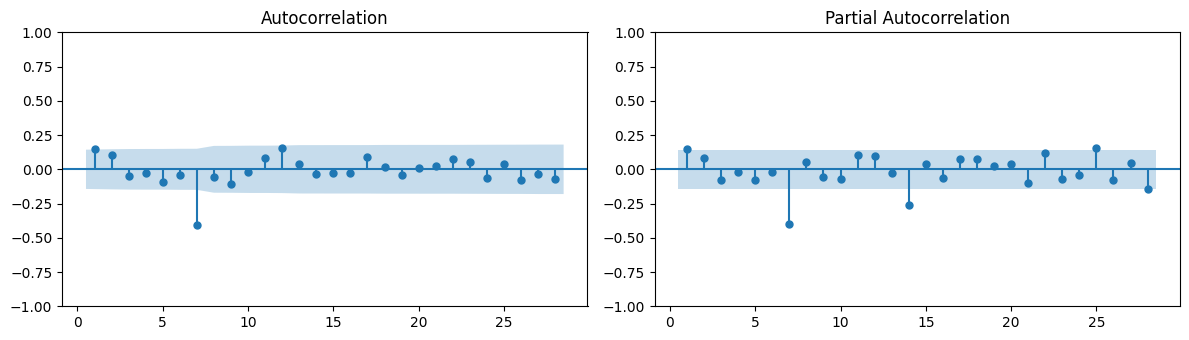

In [ ]:
z = latih.diff(7).dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(z, lags=28, zero=False, ax=ax[0]); plot_pacf(z, lags=28, zero=False, ax=ax[1])
plt.tight_layout(); plt.show()

**Interpretasi:** ACF terpotong setelah lag 7 (nilai negatif besar), sedangkan PACF meluruh pada lag musiman 7 dan 14. Pola ini menunjukkan komponen MA musiman (Q = 1). Lag 1 yang sedikit signifikan menjadikan AR(1) sebagai kandidat.

## 10. Pemilihan Orde SARIMA
Kandidat p, q = 0–2 dan P, Q = 0–1 dibandingkan menggunakan BIC.

In [ ]:
hasil = []
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    try:
        m = SARIMAX(latih, order=(p, 0, q), seasonal_order=(P, 1, Q, 7)).fit(disp=False)
        hasil.append({"order": (p, 0, q), "seasonal": (P, 1, Q, 7), "AIC": m.aic, "BIC": m.bic})
    except Exception:
        pass
kand = pd.DataFrame(hasil).sort_values("BIC").reset_index(drop=True)
kand.head(5).round(2)

,order,seasonal,AIC,BIC
0,"(1, 0, 0)","(0, 1, 1, 7)",1670.64,1680.34
1,"(0, 0, 1)","(0, 1, 1, 7)",1672.67,1682.36
2,"(1, 0, 0)","(1, 1, 1, 7)",1669.64,1682.57
3,"(0, 0, 2)","(0, 1, 1, 7)",1671.34,1684.27
4,"(0, 0, 1)","(1, 1, 1, 7)",1671.67,1684.60


**Interpretasi:** SARIMA(1,0,0)(0,1,1)₇ memiliki BIC terendah (1680,34). Model SARIMA(1,0,0)(1,1,1)₇ memiliki AIC sedikit lebih rendah (1669,64), tetapi koefisien AR musimannya tidak signifikan, sehingga dipilih model yang lebih sederhana.

## 11. Diagnosis Residual

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2624      0.076      3.457      0.001       0.114       0.411
ma.S.L7       -0.8178      0.047    -17.583      0.000      -0.909      -0.727
sigma2       412.4813     41.785      9.872      0.000     330.585     494.378


,lb_stat,lb_pvalue
7,5.877,0.554
14,15.091,0.372
21,18.603,0.611


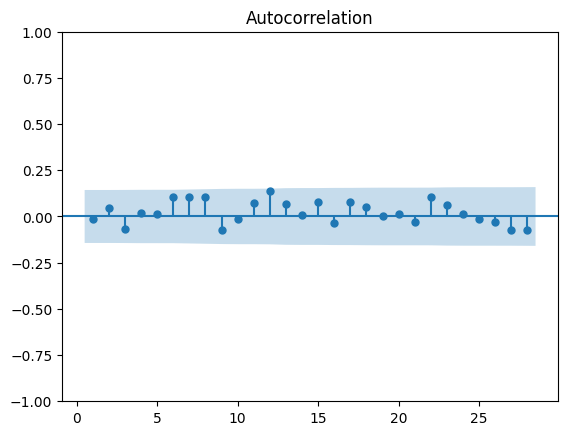

In [ ]:
orde, musiman = kand.loc[0, "order"], kand.loc[0, "seasonal"]
model = SARIMAX(latih, order=orde, seasonal_order=musiman).fit(disp=False)
print(model.summary().tables[1])

res = model.resid.iloc[7:]     # buang residual awal akibat differencing musiman
display(acorr_ljungbox(res, lags=[7, 14, 21], return_df=True).round(3))
plot_acf(res, lags=28, zero=False); plt.show()

**Interpretasi:** Koefisien AR(1) = 0,262 dan MA musiman = −0,818 keduanya signifikan (p ≤ 0,001). Uji Ljung–Box pada lag 7, 14, dan 21 memberi p = 0,554; 0,372; 0,611 (> 0,05) sehingga residual tidak berautokorelasi dan model memadai.

## 12. Prediksi pada Data Uji dan Evaluasi

,Model,MAE,RMSE,MASE
0,"SARIMA(1, 0, 0)(0, 1, 1, 7) (1 langkah)",15.2,21.00,0.79
1,"SARIMA(1, 0, 0)(0, 1, 1, 7) (49 langkah)",16.5,22.62,0.85


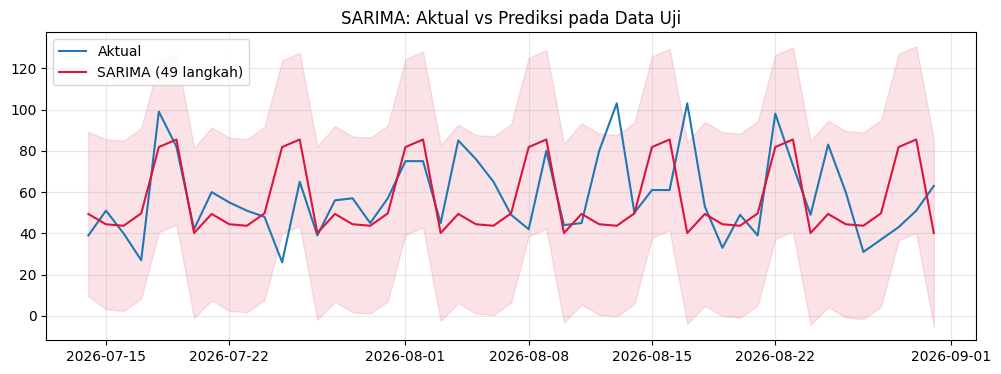

In [ ]:
# Prediksi 49 langkah sekaligus (hanya dari data latih)
ramal = model.get_forecast(len(uji))
pred_h = ramal.predicted_mean
ci = ramal.conf_int()

# Prediksi 1 langkah (parameter tetap, memakai nilai aktual sebelumnya)
pred_1 = model.apply(y).get_prediction(start=uji.index[0]).predicted_mean

tabel_sarima = pd.DataFrame({
    "Model": [f"SARIMA{orde}{musiman} (1 langkah)", f"SARIMA{orde}{musiman} (49 langkah)"],
    "MAE":  [mae(uji, pred_1), mae(uji, pred_h)],
    "RMSE": [rmse(uji, pred_1), rmse(uji, pred_h)],
    "MASE": [mase(uji, pred_1, latih), mase(uji, pred_h, latih)],
}).round(2)
display(tabel_sarima)

plt.figure(figsize=(12, 4))
plt.plot(uji, label="Aktual"); plt.plot(pred_h, label="SARIMA (49 langkah)", color="crimson")
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="crimson", alpha=.12)
plt.title("SARIMA: Aktual vs Prediksi pada Data Uji"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Interpretasi:** SARIMA menghasilkan MAE 15,20 (1 langkah) dan 16,50 (49 langkah), lebih kecil daripada naif musiman (20,94 dan 18,65), atau perbaikan sekitar 27,4% dan 11,5%. MASE di bawah 1 (0,79 dan 0,85) berarti galatnya lebih kecil daripada galat naif musiman pada data latih. Grafik menunjukkan SARIMA mengikuti pola mingguan, tetapi tidak menangkap lonjakan tertentu pada data uji. Selisih pada prediksi 49 langkah tergolong kecil.
**Keterbatasan:** Interval kepercayaan sempat bernilai negatif, dan periode uji hanya 49 hari. Strategi prediksi akhir akan disesuaikan dengan kesepakatan kelompok.


## Kesimpulan Progress 2
Model SARIMA(1,0,0)(0,1,1)₇ memadai secara diagnostik dan mengungguli naif musiman pada data uji. Tahap selanjutnya adalah membangun model LSTM pada pembagian data yang sama.